# Economic data v1

Question: **Since 2000, how do GDP growth, inflation, and unemployment move together — globally, and in a few large economies?**

All countries are in the cache. The World Bank **World** aggregate is the honest global series (size-weighted). The six large economies are the readable close-up. Plotting 200 overlapping country lines would look busier, not clearer.

Charts are shown here and also written to `figures/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

ROOT = Path.cwd()
if ROOT.name != "economic-data":
    candidate = ROOT / "experiments" / "economic-data"
    if candidate.exists():
        ROOT = candidate

sys.path.insert(0, str(ROOT))
from fetch_world_bank import CACHE_PATH, load_or_fetch
from render_figures import render, to_wide, latest_year_with_coverage

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)

long = load_or_fetch(CACHE_PATH)
wide = to_wide(long)
focus = wide[wide["is_focus"]].copy()
world = wide[wide["is_world"]].copy()
countries = wide[~wide["is_aggregate"]].copy()

print(
    f"{countries['iso'].nunique()} countries, "
    f"{int(long['is_world'].any())} world aggregate, "
    f"years {int(wide['year'].min())}–{int(wide['year'].max())}"
)
long.head()

215 countries, 1 world aggregate, years 2000–2025


,country,iso,year,indicator,indicator_code,value,region,income_level,is_aggregate,is_focus,is_world
0,Aruba,ABW,2000,gdp_growth,NY.GDP.MKTP.KD.ZG,7.622921,Latin America & Caribbean,High income,False,False,False
1,Aruba,ABW,2000,inflation,FP.CPI.TOTL.ZG,4.044021,Latin America & Caribbean,High income,False,False,False
2,Aruba,ABW,2000,unemployment,SL.UEM.TOTL.ZS,NaN,Latin America & Caribbean,High income,False,False,False
3,Aruba,ABW,2001,gdp_growth,NY.GDP.MKTP.KD.ZG,4.182002,Latin America & Caribbean,High income,False,False,False
4,Aruba,ABW,2001,inflation,FP.CPI.TOTL.ZG,2.883604,Latin America & Caribbean,High income,False,False,False


In [2]:
print("Missing values in the six-country panel:")
print(focus[["gdp_growth", "inflation", "unemployment"]].isna().sum())
focus.describe()

Missing values in the six-country panel:
gdp_growth      0
inflation       1
unemployment    0
dtype: int64


,year,gdp_growth,inflation,unemployment
count,156.000000,156.000000,155.000000,156.000000
mean,2012.500000,3.462749,3.191526,6.122327
std,7.524155,3.659546,2.876426,2.551882
min,2000.000000,-5.935941,-1.352837,2.351000
25%,2006.000000,1.297346,1.247584,4.292500
50%,2012.500000,2.911740,2.621050,5.093000
75%,2019.000000,6.210543,4.852401,7.646750
max,2025.000000,14.150771,14.714920,13.697000


## Global picture first

The World aggregate is closer to "what happened to the world economy" than an unweighted average of every country (which would treat Luxembourg and China as equals).

In [3]:
paths = render(long)
print("Saved:")
for path in paths:
    print(" ", path)

Saved:
  /Users/kathycui/data-playground/experiments/economic-data/figures/focus_trends.png
  /Users/kathycui/data-playground/experiments/economic-data/figures/world_vs_focus.png
  /Users/kathycui/data-playground/experiments/economic-data/figures/focus_relationships.png
  /Users/kathycui/data-playground/experiments/economic-data/figures/global_inflation_distribution.png


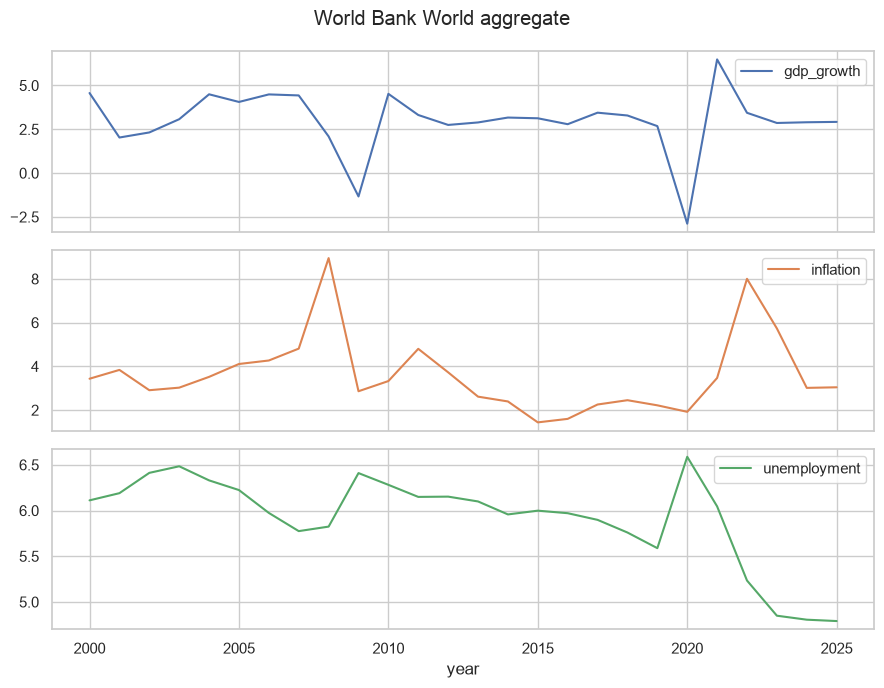

In [4]:
world.set_index("year")[["gdp_growth", "inflation", "unemployment"]].plot(
    subplots=True, figsize=(9, 7), title="World Bank World aggregate"
)
plt.tight_layout()
plt.show()

In [5]:
year = latest_year_with_coverage(countries, "inflation")
snap = countries[countries["year"] == year].dropna(subset=["inflation"])
print(f"Latest well-covered inflation year: {year} ({len(snap)} countries)")
print(snap["inflation"].describe().round(2))
print("\nFocus countries in that year:")
display(snap.loc[snap["is_focus"], ["country", "inflation", "gdp_growth", "unemployment"]].round(2))

Latest well-covered inflation year: 2024 (176 countries)
count    176.00
mean       7.41
std       19.54
min       -6.60
25%        1.72
50%        3.01
75%        4.88
max      219.88
Name: inflation, dtype: float64

Focus countries in that year:


,country,inflation,gdp_growth,unemployment
770,Brazil,4.37,3.42,6.80
1178,China,0.22,4.96,4.59
2258,Germany,2.26,-0.50,3.40
2802,India,4.95,7.10,4.17
3034,Japan,2.74,-0.24,2.50
6353,United States,2.95,2.79,4.02


## Six-country close-up

These six are large enough to matter globally and different enough to show that one "world" line hides a lot.

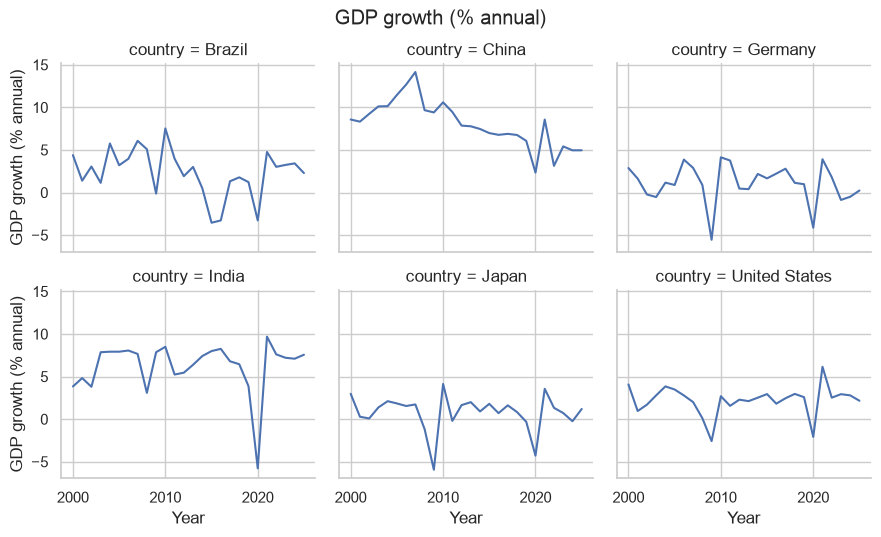

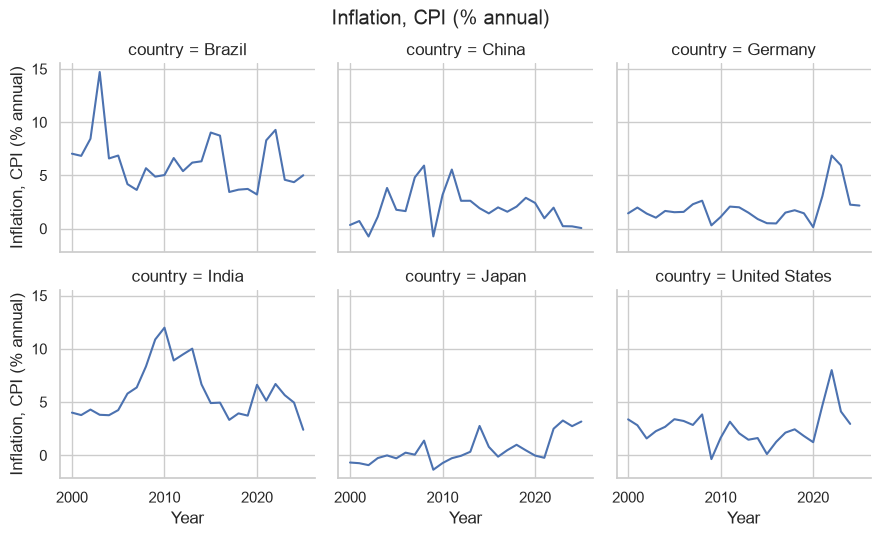

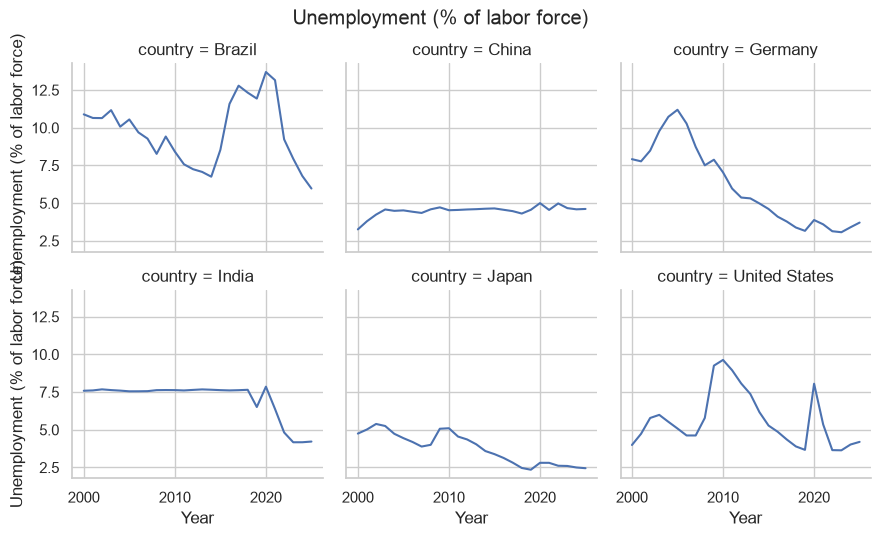

In [6]:
indicators = ["gdp_growth", "inflation", "unemployment"]
titles = {
    "gdp_growth": "GDP growth (% annual)",
    "inflation": "Inflation, CPI (% annual)",
    "unemployment": "Unemployment (% of labor force)",
}

for col in indicators:
    g = sns.relplot(
        data=focus,
        x="year",
        y=col,
        col="country",
        col_wrap=3,
        kind="line",
        height=2.6,
        aspect=1.15,
    )
    g.set_axis_labels("Year", titles[col])
    g.fig.suptitle(titles[col], y=1.03)
    plt.show()

## Relationships (six-country sample)

In [7]:
corr = focus[indicators].corr()
print("Pooled correlations (country-years, pairwise complete):")
display(corr.round(3))

print("\nWithin-country correlations:")
display(
    focus.groupby("country")[indicators]
    .corr()
    .unstack()
    .loc[:, [("inflation", "unemployment"), ("gdp_growth", "inflation")]]
    .round(3)
)

Pooled correlations (country-years, pairwise complete):


,gdp_growth,inflation,unemployment
gdp_growth,1.000,0.185,-0.097
inflation,0.185,1.000,0.453
unemployment,-0.097,0.453,1.000



Within-country correlations:


,inflation,gdp_growth
,unemployment,inflation
country,,
Brazil,0.063,-0.144
China,0.183,0.300
Germany,-0.296,0.152
India,0.240,-0.023
Japan,-0.690,0.060
United States,-0.463,0.416


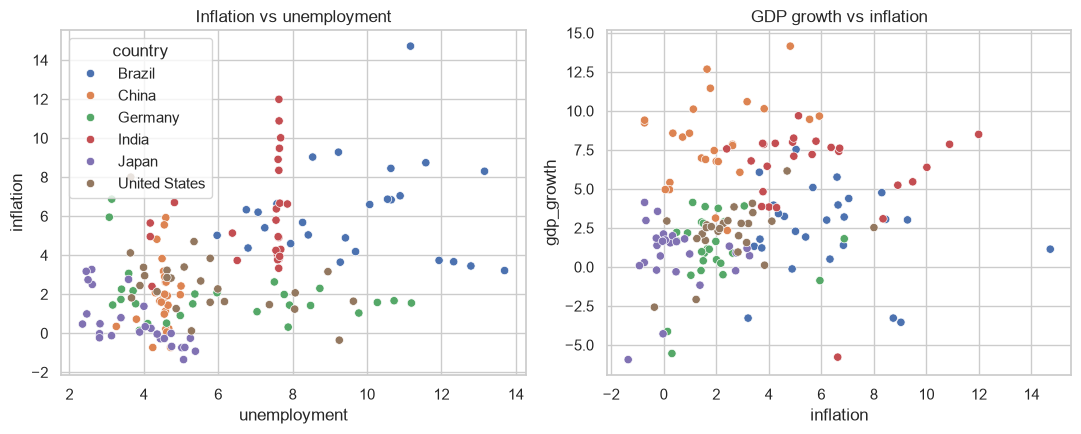

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(data=focus, x="unemployment", y="inflation", hue="country", ax=axes[0])
axes[0].set_title("Inflation vs unemployment")
sns.scatterplot(data=focus, x="inflation", y="gdp_growth", hue="country", ax=axes[1], legend=False)
axes[1].set_title("GDP growth vs inflation")
fig.tight_layout()
plt.show()

## Regression: inflation ~ unemployment + country

Pooled OLS on the six-country panel only. Running this on every country with equal weight would mix incomparable labor markets and let tiny economies dominate the slope. Negative unemployment coefficient would match a Phillips-curve-style pattern. Descriptive only.

In [9]:
model_df = focus.dropna(subset=["inflation", "unemployment"]).copy()
model = smf.ols("inflation ~ unemployment + C(country)", data=model_df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              inflation   R-squared:                       0.567
Model:                            OLS   Adj. R-squared:                  0.550
Method:                 Least Squares   F-statistic:                     32.34
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           1.12e-24
Time:                        19:18:31   Log-Likelihood:                -318.28
No. Observations:                 155   AIC:                             650.6
Df Residuals:                     148   BIC:                             671.9
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

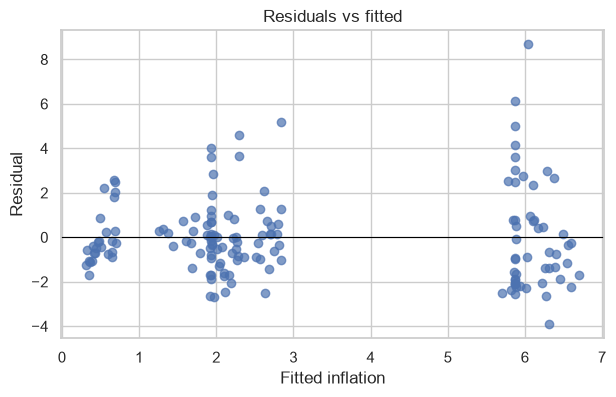

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(model.fittedvalues, model.resid, alpha=0.7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Fitted inflation")
ax.set_ylabel("Residual")
ax.set_title("Residuals vs fitted")
plt.show()

## What to take from this (and what not to)

- **Global vs local:** the World aggregate is the wide-angle shot. The six-country charts are the zoom. More countries in a line chart is usually worse, not better.
- **Distribution:** the latest-year inflation histogram shows how unusual (or not) the six countries are versus everyone else.
- **Co-movement:** pooled correlations mix different economies. The within-country table is the more honest Phillips-curve check.
- **Regression:** the unemployment slope is an average association after country intercepts, not a causal effect.
- **Caveats:** annual data, missing country-years (especially unemployment), World Bank lags, correlation ≠ causation.